<a href="https://colab.research.google.com/github/fadeeva/quant_finance_projects/blob/main/01_Analysis_and_Modeling_of_Stock_Returns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analysis and Modeling of Stock Returns

In [11]:
import numpy as np
import pandas as pd

import datetime as dt
import yfinance as yf

from scipy import stats

import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('ggplot')

In [2]:
rng = np.random.default_rng(42)

## Get Data

In [8]:
tickers  = ['AAPL', 'AMZN', 'GOOGL', 'SPY', 'NVDA']

data = yf.download(
    tickers,
    dt.datetime(2022, 1, 1), dt.datetime.now(),
    auto_adjust=True
)
data = data['Close']

data.head()

[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,GOOGL,NVDA,SPY
Date,,,,,
2022-01-03,177.786392,170.404495,143.624802,29.992580,448.373016
2022-01-04,175.529999,167.522003,143.038406,29.165127,448.222900
2022-01-05,170.860916,164.356995,136.476349,27.486311,439.616058
2022-01-06,168.008652,163.253998,136.449112,28.057865,439.203094
2022-01-07,168.174728,162.554001,135.725464,27.130838,437.466736


In [9]:
df = data.copy()

## Log Returns

$$
r_t = ln(\frac{p_t}{p_{t-1}})
$$

In [10]:
df = pd.concat([df, np.log(df / df.shift(1)).add_suffix('_log_ret')], axis=1)
df.dropna(inplace=True)
df.head()

Ticker,AAPL,AMZN,GOOGL,NVDA,SPY,AAPL_log_ret,AMZN_log_ret,GOOGL_log_ret,NVDA_log_ret,SPY_log_ret
Date,,,,,,,,,,
2022-01-04,175.529999,167.522003,143.038406,29.165127,448.222900,-0.012773,-0.017060,-0.004091,-0.027976,-0.000335
2022-01-05,170.860916,164.356995,136.476349,27.486311,439.616058,-0.026960,-0.019074,-0.046962,-0.059286,-0.019389
2022-01-06,168.008652,163.253998,136.449112,28.057865,439.203094,-0.016834,-0.006734,-0.000200,0.020581,-0.000940
2022-01-07,168.174728,162.554001,135.725464,27.130838,437.466736,0.000988,-0.004297,-0.005318,-0.033598,-0.003961
2022-01-10,168.194305,161.485992,137.362381,27.283180,436.922302,0.000116,-0.006592,0.011988,0.005599,-0.001245


### Cummulative Returns Visualization

$$
R^{cumm}_T = e^{\sum^T_{t=1}{r^{log}_t}} - 1
$$

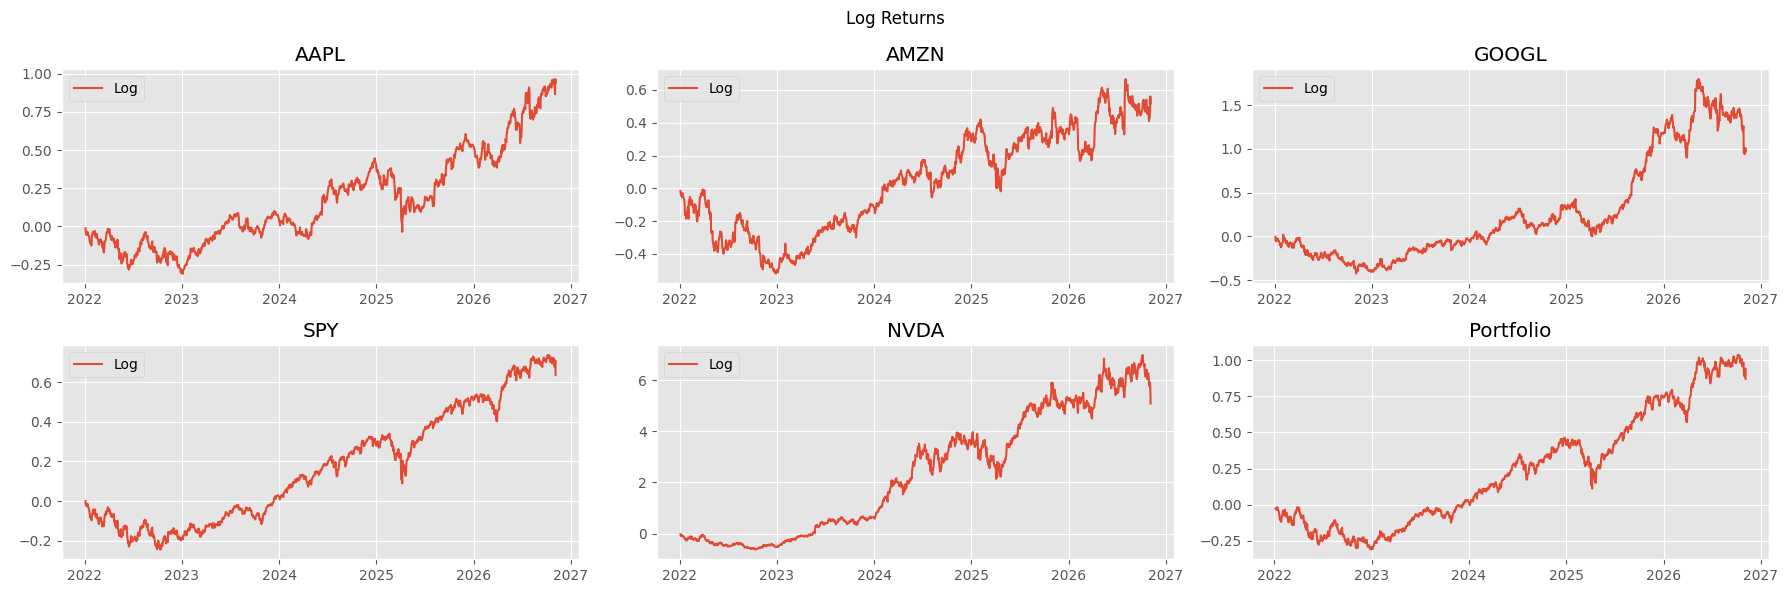

In [16]:
fig, axs = plt.subplots(2, 3, figsize=(18, 6))
axs = axs.flatten()

for i, ticker in enumerate(tickers):
    axs[i].plot(np.exp(df[f'{ticker}_log_ret'].cumsum()) - 1, label='Log')
    axs[i].set_title(f'{ticker}')
    axs[i].legend()

axs[5].plot(np.exp((np.log(df.sum(axis=1) / df.sum(axis=1).shift(1)).dropna()).cumsum()) - 1)
axs[5].set_title('Portfolio')

fig.suptitle('Log Returns')
plt.tight_layout();